In [1]:
# ============================================================
# CELL 1 ▸ Imports
# ============================================================
import subprocess, sys
for pkg in ['tensorflow','numpy','pandas','scipy',
            'matplotlib','seaborn','scikit-learn','tqdm']:
    imp = 'sklearn' if pkg=='scikit-learn' else pkg
    try: __import__(imp)
    except ImportError:
        subprocess.check_call([sys.executable,'-m','pip','install',
                               '-q',pkg],
                              stdout=subprocess.DEVNULL,
                              stderr=subprocess.DEVNULL)

import os, gc, json, time, zipfile, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from scipy import stats as scipy_stats
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, applications

tf.get_logger().setLevel('ERROR')

# Enable mixed precision (FP16 activations, FP32 weights → ~2× speedup)
keras.mixed_precision.set_global_policy('mixed_float16')

strategy = tf.distribute.MirroredStrategy()
N_GPUS   = strategy.num_replicas_in_sync

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi':150,'savefig.dpi':300,
                     'font.size':11,'savefig.bbox':'tight'})

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f'TF {tf.__version__}  |  GPUs: {N_GPUS}')
print(f'Mixed precision policy: {keras.mixed_precision.global_policy().name}')
print(f'MirroredStrategy replicas: {N_GPUS}')
print('Imports complete.')

TF 2.20.0  |  GPUs: 2
Mixed precision policy: mixed_float16
MirroredStrategy replicas: 2
Imports complete.


I0000 00:00:1786791040.907824      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786791040.910633      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [2]:
# ============================================================
# CELL 2 ▸ Configuration
# ============================================================
# ⚙️  Set P4A_DIR to the Part 4A Kaggle dataset (specs_f16.npy + segments.csv)

P4A_DIR  = '/kaggle/input/datasets/tarek1074/part4a-results'
speces = '/kaggle/input/datasets/tarek1074/specs-f16-npy'

SPECS_PATH = os.path.join(speces, 'specs_f16.npy')   # 5.96 GB float16 memmap
SEG_CSV    = os.path.join(P4A_DIR, 'segments.csv')

WORK_DIR   = '/kaggle/working'
OUT_DIR    = os.path.join(WORK_DIR, 'part5a_v3')
FIG_DIR    = os.path.join(OUT_DIR,  'figures')
MDL_DIR    = os.path.join(OUT_DIR,  'models')
LOG_DIR    = os.path.join(OUT_DIR,  'logs')
for d in [OUT_DIR, FIG_DIR, MDL_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

# Spectrogram parameters — must match Part 4A
IMG_H, IMG_W, IMG_C = 128, 128, 3

# Training
N_FOLDS  = 5
SEED     = 42

# Phase 1: freeze EfficientNet, train head only — large batch, fast
EPOCHS_P1  = 5
LR_P1      = 1e-3
BATCH_P1   = 64 * max(1, N_GPUS)    # 128 with 2×T4

# Phase 2: unfreeze top 30% of EfficientNet + head — smaller batch, full gradients
EPOCHS_P2  = 30
LR_P2      = 1e-4
PATIENCE_P2= 10
BATCH_P2   = 32 * max(1, N_GPUS)    # 64 with 2×T4
UNFREEZE_FRAC = 0.30                  # unfreeze top 30% of EfficientNet layers

CLASS_NAMES = [
    'Bangla_Band_Collection','Bangla_ancholik','Bangla_baby_rhymes',
    'Bangla_rabindra_sangeet','Bangla_romantic','Classic_Songs_',
    'Islamic_Melody','Nazrul_Geeti_',
]
CLASS_SHORT = {
    'Bangla_Band_Collection':'Band','Bangla_ancholik':'Ancholik',
    'Bangla_baby_rhymes':'Rhymes','Bangla_rabindra_sangeet':'Rabindra',
    'Bangla_romantic':'Romantic','Classic_Songs_':'Classic',
    'Islamic_Melody':'Islamic','Nazrul_Geeti_':'Nazrul',
}
N_CLASSES   = len(CLASS_NAMES)
SHORT_NAMES = [CLASS_SHORT[c] for c in CLASS_NAMES]
le          = LabelEncoder().fit(CLASS_NAMES)

print('Configuration loaded.')
print(f'  N_GPUS   : {N_GPUS}')
print(f'  BATCH_P1 : {BATCH_P1}  (Phase 1 — head only)')
print(f'  BATCH_P2 : {BATCH_P2}  (Phase 2 — backbone gradients)')
print(f'  UNFREEZE : top {UNFREEZE_FRAC*100:.0f}% of EfficientNet layers')

Configuration loaded.
  N_GPUS   : 2
  BATCH_P1 : 128  (Phase 1 — head only)
  BATCH_P2 : 64  (Phase 2 — backbone gradients)
  UNFREEZE : top 30% of EfficientNet layers


In [3]:
# ============================================================
# CELL 3 ▸ Load Specs Memmap + Segment Metadata
# ============================================================
print('Loading spectrogram memmap ...')
assert os.path.exists(SPECS_PATH), (
    f'specs_f16.npy not found: {SPECS_PATH}\\n'
    f'Check that the Part 4A dataset is added to this notebook.')
assert os.path.exists(SEG_CSV), (
    f'segments.csv not found: {SEG_CSV}')

ALL_SPECS = np.load(SPECS_PATH, mmap_mode='r')   # float16, memory-mapped
print(f'  ALL_SPECS : {ALL_SPECS.shape}  {ALL_SPECS.dtype}'
      f'  ({ALL_SPECS.nbytes/1e9:.2f} GB)')

# Validate non-zero
samp = np.random.RandomState(42).choice(ALL_SPECS.shape[0], 50, replace=False)
n_nz = sum(1 for i in samp if np.abs(ALL_SPECS[i]).max() > 1e-6)
assert n_nz >= 40, f'Only {n_nz}/50 non-zero — specs corrupted.'
print(f'  Validity  : {n_nz}/50 non-zero ✅')

seg_df = pd.read_csv(SEG_CSV)
assert len(seg_df) == ALL_SPECS.shape[0], (
    f'Row mismatch: csv={len(seg_df)} specs={ALL_SPECS.shape[0]}')

ALL_LABELS = seg_df['label_id'].values.astype(np.int32)
ALL_FOLDS  = seg_df['fold'].values.astype(np.int32)
ALL_LBLSTR = seg_df['label'].values
N_SEGS     = len(seg_df)

print(f'\\n  {N_SEGS:,} segments  |  {N_FOLDS} folds')
for k in range(N_FOLDS):
    sub = seg_df[seg_df['fold']==k]
    print(f'  Fold {k}: {len(sub):,} segs | {sub["label"].nunique()}/8 classes')

ok = all(seg_df[seg_df['fold']==k]['label'].nunique()==N_CLASSES
         for k in range(N_FOLDS))
print('✅ All 8 classes in every fold.' if ok else '⚠️  Missing classes!')

Loading spectrogram memmap ...
  ALL_SPECS : (60579, 128, 128, 3)  float16  (5.96 GB)
  Validity  : 50/50 non-zero ✅
\n  60,579 segments  |  5 folds
  Fold 0: 11,609 segs | 8/8 classes
  Fold 1: 12,922 segs | 8/8 classes
  Fold 2: 11,769 segs | 8/8 classes
  Fold 3: 13,630 segs | 8/8 classes
  Fold 4: 10,649 segs | 8/8 classes
✅ All 8 classes in every fold.


In [4]:
# ============================================================
# CELL 4 ▸ Data Pipeline  (reuse Part 4A pipeline)
# ============================================================
# Identical to Part 4A/4B/4C — sample_weight in 3rd element,
# prefetch limited, mixed precision compatible.

def make_sw(label_strings):
    counts = np.array([(label_strings==c).sum()
                       for c in CLASS_NAMES], dtype=np.float64)
    w = np.sqrt(counts.max()/(counts+1e-8))
    w = (w/w.mean()).astype(np.float32)
    d = {cls:float(w[i]) for i,cls in enumerate(CLASS_NAMES)}
    return np.array([d[s] for s in label_strings], dtype=np.float32)

def spec_aug(x):
    '''SpecAugment: random time + frequency masking.'''
    t  = tf.random.uniform((),1,31,dtype=tf.int32)
    t0 = tf.random.uniform((),0,IMG_W-t,dtype=tf.int32)
    ti = tf.range(IMG_W)
    tm = tf.cast(tf.logical_or(ti<t0,ti>=t0+t),tf.float32)
    x  = x * tm[tf.newaxis,:,tf.newaxis]
    f  = tf.random.uniform((),1,17,dtype=tf.int32)
    f0 = tf.random.uniform((),0,IMG_H-f,dtype=tf.int32)
    fi = tf.range(IMG_H)
    fm = tf.cast(tf.logical_or(fi<f0,fi>=f0+f),tf.float32)
    return x * fm[:,tf.newaxis,tf.newaxis]

def build_train_ds(gidx, lids, lbls, bs, augment=True):
    '''Yields (spec_f32, y_onehot, sample_weight).'''
    _i=np.asarray(gidx,np.int64); _l=np.asarray(lids,np.int32)
    _w=make_sw(lbls); n=len(_i)
    def _ld(pos):
        p=int(pos)
        return ALL_SPECS[_i[p]].astype(np.float32),_l[p],_w[p]
    ds=tf.data.Dataset.range(n)
    ds=ds.shuffle(min(10000,n),seed=SEED,reshuffle_each_iteration=True)
    ds=ds.map(lambda p:tf.numpy_function(_ld,[p],[tf.float32,tf.int32,tf.float32]),
              num_parallel_calls=tf.data.AUTOTUNE)
    ds=ds.map(lambda x,y,w:(tf.ensure_shape(x,[IMG_H,IMG_W,IMG_C]),
                             tf.ensure_shape(y,[]),
                             tf.ensure_shape(w,[])),
              num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds=ds.map(lambda x,y,w:(spec_aug(x),y,w),
                  num_parallel_calls=tf.data.AUTOTUNE)
    ds=ds.map(lambda x,y,w:(x,tf.one_hot(y,N_CLASSES),w),
              num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs).prefetch(4)

def build_val_ds(gidx, lids, bs):
    '''Yields (spec_f32, y_onehot) — no weights.'''
    _i=np.asarray(gidx,np.int64); _l=np.asarray(lids,np.int32); n=len(_i)
    def _ld(pos):
        p=int(pos)
        return ALL_SPECS[_i[p]].astype(np.float32),_l[p]
    ds=tf.data.Dataset.range(n)
    ds=ds.map(lambda p:tf.numpy_function(_ld,[p],[tf.float32,tf.int32]),
              num_parallel_calls=tf.data.AUTOTUNE)
    ds=ds.map(lambda x,y:(tf.ensure_shape(x,[IMG_H,IMG_W,IMG_C]),
                           tf.one_hot(tf.ensure_shape(y,[]),N_CLASSES)),
              num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs).prefetch(2)

def predict_batched(model, gidx, bs=256):
    n=len(gidx); out=np.zeros((n,N_CLASSES),dtype=np.float32)
    for s in range(0,n,bs):
        e=min(s+bs,n)
        out[s:e]=model.predict(
            ALL_SPECS[gidx[s:e]].astype(np.float32),verbose=0)
    return out

print('Data pipeline ready.')

Data pipeline ready.


In [5]:
# ============================================================
# CELL 5 ▸ EfficientNetB0 Model + MacroF1 Callback
# ============================================================

def build_efficientnet(n_cls=N_CLASSES, trainable_base=False):
    '''
    EfficientNetB0 pre-trained on ImageNet.
    Final Dense uses float32 (required for mixed precision stability).
    '''
    base = applications.EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_H, IMG_W, IMG_C),
    )
    base.trainable = trainable_base

    inp = keras.Input(shape=(IMG_H, IMG_W, IMG_C))
    # EfficientNet expects pixel values ~[0,255]; our specs are ~[-3,3]
    # Rescale to [0,255] range for compatibility
    x   = layers.Rescaling(scale=255.0/6.0, offset=0.5*255)(inp)
    x   = base(x, training=trainable_base)
    x   = layers.GlobalAveragePooling2D()(x)
    x   = layers.BatchNormalization()(x)
    x   = layers.Dense(512)(x)
    x   = layers.BatchNormalization()(x)
    x   = layers.Activation('relu')(x)
    x   = layers.Dropout(0.4)(x)
    x   = layers.Dense(256, activation='relu')(x)
    x   = layers.Dropout(0.3)(x)
    # MUST be float32 for mixed precision stability
    out = layers.Dense(n_cls, activation='softmax', dtype='float32')(x)

    model = keras.Model(inputs=inp, outputs=out,
                        name='EfficientNetB0_FT')
    return model, base


def unfreeze_top_fraction(base, fraction=UNFREEZE_FRAC):
    '''Unfreeze the top `fraction` of EfficientNet layers for Phase 2.'''
    base.trainable = True
    n_layers     = len(base.layers)
    freeze_until = int(n_layers * (1 - fraction))
    for layer in base.layers[:freeze_until]:
        layer.trainable = False
    n_trainable = sum(1 for l in base.layers if l.trainable)
    print(f'  Unfrozen: {n_trainable}/{n_layers} layers '
          f'(top {fraction*100:.0f}%)')
    return base


class MacroF1CB(keras.callbacks.Callback):
    def __init__(self, val_gi, val_lids, patience=PATIENCE_P2):
        super().__init__()
        self.vgi    = np.asarray(val_gi, np.int64)
        self.vl     = np.asarray(val_lids, np.int32)
        self.pat    = patience
        self.best   = 0.0; self.best_w = None
        self.wait   = 0;   self.best_ep = 0
        self.history= []

    def on_epoch_end(self, epoch, logs=None):
        probs  = predict_batched(self.model, self.vgi)
        ypred  = probs.argmax(1)
        f1 = float(f1_score(self.vl, ypred,
                             average='macro', zero_division=0))
        self.history.append(f1)
        if f1 > self.best:
            self.best   = f1
            self.best_w = self.model.get_weights()
            self.best_ep= epoch+1
            self.wait   = 0
        else:
            self.wait  += 1
        if self.wait >= self.pat:
            self.model.stop_training = True
            if self.best_w:
                self.model.set_weights(self.best_w)
        if (epoch+1) % 5 == 0:
            print(f'  ep {epoch+1:3d}  val_f1={f1:.4f}'
                  f'  best={self.best:.4f}@ep{self.best_ep}')


# Quick param count check
_m, _b = build_efficientnet(trainable_base=False)
n_p1 = sum(p.numpy().size for p in _m.trainable_weights)
del _m, _b; keras.backend.clear_session()
print(f'Phase 1 trainable params (head only): {n_p1:,}')

_m, _b = build_efficientnet(trainable_base=True)
unfreeze_top_fraction(_b, UNFREEZE_FRAC)
n_p2 = sum(p.numpy().size for p in _m.trainable_weights)
del _m, _b; keras.backend.clear_session()
print(f'Phase 2 trainable params (top {UNFREEZE_FRAC*100:.0f}% + head): {n_p2:,}')

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Phase 1 trainable params (head only): 792,840
  Unfrozen: 72/238 layers (top 30%)
Phase 2 trainable params (top 30% + head): 3,871,972


In [6]:
# ============================================================
# CELL 6 ▸ 5-Fold CV — Phase 1 + Phase 2
# ============================================================
print('='*55)
print('  EfficientNetB0 Fine-Tuning — 5-Fold CV')
print('='*55)
print()

CV_FOLD_MET  = []
P1_F1S       = []
best_model_f1= -1.0

for k in range(N_FOLDS):
    t0 = time.time()

    tr_mask = ALL_FOLDS != k; te_mask = ALL_FOLDS == k
    tr_gi   = np.where(tr_mask)[0]; te_gi = np.where(te_mask)[0]
    y_tr    = ALL_LABELS[tr_mask]

    sss = StratifiedShuffleSplit(1, test_size=0.1, random_state=SEED+k)
    loc_tr, loc_vl = next(sss.split(tr_gi, y_tr))
    trn_gi = tr_gi[loc_tr]; val_gi = tr_gi[loc_vl]

    # ── PHASE 1: frozen EfficientNet, train head only ──────
    ds_tr_p1 = build_train_ds(trn_gi, ALL_LABELS[trn_gi],
                               ALL_LBLSTR[trn_gi],
                               BATCH_P1, augment=True)
    ds_vl    = build_val_ds(val_gi, ALL_LABELS[val_gi],
                             BATCH_P1)

    keras.backend.clear_session()
    with strategy.scope():
        model, base = build_efficientnet(trainable_base=False)
        model.compile(
            optimizer=keras.optimizers.Adam(LR_P1),
            loss='categorical_crossentropy',
            metrics=['accuracy'])

    model.fit(ds_tr_p1,
              validation_data=ds_vl,
              epochs=EPOCHS_P1,
              verbose=0)

    p1_probs = predict_batched(model, val_gi)
    p1_f1    = float(f1_score(ALL_LABELS[val_gi], p1_probs.argmax(1),
                               average='macro', zero_division=0))
    P1_F1S.append(p1_f1)

    # Save Phase 1 head weights for Phase 2 warm start
    p1_weights = model.get_weights()
    t1 = time.time()
    print(f'  Fold {k+1}/5  Phase1: val_f1={p1_f1:.4f}  '
          f'({(t1-t0)/60:.1f} min) → Phase 2 ...')

    # ── PHASE 2: unfreeze top 30% + head, fine-tune ────────
    ds_tr_p2 = build_train_ds(trn_gi, ALL_LABELS[trn_gi],
                               ALL_LBLSTR[trn_gi],
                               BATCH_P2, augment=True)
    ds_vl_p2 = build_val_ds(val_gi, ALL_LABELS[val_gi],
                              BATCH_P2)

    keras.backend.clear_session()
    with strategy.scope():
        model, base = build_efficientnet(trainable_base=False)
        # Warm start from Phase 1
        model.set_weights(p1_weights)
        # Unfreeze top fraction of EfficientNet
        unfreeze_top_fraction(base, UNFREEZE_FRAC)
        # Recompile with smaller LR
        model.compile(
            optimizer=keras.optimizers.Adam(LR_P2),
            loss='categorical_crossentropy',
            metrics=['accuracy'])

    f1cb  = MacroF1CB(val_gi, ALL_LABELS[val_gi])
    lrcb  = keras.callbacks.ReduceLROnPlateau(
                monitor='val_loss', factor=0.5, patience=7,
                min_lr=1e-7, verbose=0)
    logcb = keras.callbacks.CSVLogger(
                os.path.join(LOG_DIR, f'effnet_fold{k}.csv'))

    # sample_weight in ds_tr_p2 (3rd element) — NO class_weight in fit()
    model.fit(ds_tr_p2,
              validation_data=ds_vl_p2,
              epochs=EPOCHS_P2,
              callbacks=[f1cb, lrcb, logcb],
              verbose=0)

    # Evaluate test fold
    probs  = predict_batched(model, te_gi)
    y_pred = probs.argmax(1)
    y_te   = ALL_LABELS[te_mask]

    mf1  = float(f1_score(y_te,y_pred,average='macro',   zero_division=0))
    wf1  = float(f1_score(y_te,y_pred,average='weighted',zero_division=0))
    acc  = float(accuracy_score(y_te,y_pred))
    pcf1 = [float(f1_score((y_te==i).astype(int),
                            (y_pred==i).astype(int),zero_division=0))
            for i in range(N_CLASSES)]

    CV_FOLD_MET.append({
        'macro_f1'    : mf1,
        'weighted_f1' : wf1,
        'accuracy'    : acc,
        'per_class_f1': pcf1,
        'phase1_f1'   : p1_f1,
        'best_epoch_p2': f1cb.best_ep,
        'f1_history_p2': f1cb.history,
        'y_pred'      : y_pred.tolist(),
        'y_true'      : y_te.tolist(),
    })

    if mf1 > best_model_f1:
        best_model_f1 = mf1
        model.save(os.path.join(MDL_DIR,'efficientnet_best.keras'))

    elapsed = time.time()-t0
    print(f'  Fold {k+1}/5  P1={p1_f1:.4f} → P2={mf1:.4f}'
          f'  (Δ={mf1-p1_f1:+.4f})'
          f'  best_ep_p2={f1cb.best_ep}  ({elapsed/60:.1f} min)')
    del model, base; gc.collect()

# ── Summary ───────────────────────────────────────────────────
mf1s  = np.array([m['macro_f1'] for m in CV_FOLD_MET])
t95   = scipy_stats.t.ppf(0.975, df=N_FOLDS-1)
ci_eff= float(t95*mf1s.std(ddof=1)/np.sqrt(N_FOLDS))
eff_sum={
    'model'             : 'EfficientNetB0_FT',
    'pretrain'          : 'ImageNet (fine-tuned on mel spectrograms)',
    'fine_tuned_layers' : f'top {UNFREEZE_FRAC*100:.0f}% EfficientNet + head',
    'n_folds'           : N_FOLDS,
    'macro_f1_mean'     : round(float(mf1s.mean()),4),
    'macro_f1_std'      : round(float(mf1s.std(ddof=1)),4),
    'macro_f1_ci95'     : round(ci_eff,4),
    'macro_f1_min'      : round(float(mf1s.min()),4),
    'macro_f1_max'      : round(float(mf1s.max()),4),
    'weighted_f1_mean'  : round(float(np.mean([m['weighted_f1'] for m in CV_FOLD_MET])),4),
    'accuracy_mean'     : round(float(np.mean([m['accuracy']    for m in CV_FOLD_MET])),4),
    'per_fold_macro_f1' : mf1s.tolist(),
    'phase1_f1s'        : P1_F1S,
    'include_in_paper'  : True,
    'paper_label'       : 'EfficientNetB0 (ImageNet pretrain, fine-tuned)',
}
m,s,c = eff_sum['macro_f1_mean'],eff_sum['macro_f1_std'],eff_sum['macro_f1_ci95']
print(f'\\n  EfficientNetB0 Macro-F1: {m:.4f} +/- {s:.4f}')
print(f'  95% CI (t-dist df=4)   : [{m-c:.4f}, {m+c:.4f}]')
print(f'  Per fold: {[round(v,4) for v in mf1s.tolist()]}')
p1m = np.mean(P1_F1S)
print(f'  Phase 1 mean: {p1m:.4f} → Phase 2: {m:.4f}'
      f'  (Δ={m-p1m:+.4f} from fine-tuning)')

  EfficientNetB0 Fine-Tuning — 5-Fold CV



E0000 00:00:1786791065.797412      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_FT_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  Fold 1/5  Phase1: val_f1=0.5959  (3.5 min) → Phase 2 ...
  Unfrozen: 72/238 layers (top 30%)


E0000 00:00:1786791283.208909      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_FT_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.7252  best=0.7252@ep5
  ep  10  val_f1=0.7731  best=0.7760@ep9
  ep  15  val_f1=0.8168  best=0.8168@ep15
  ep  20  val_f1=0.8350  best=0.8394@ep19
  ep  25  val_f1=0.8577  best=0.8577@ep25
  ep  30  val_f1=0.8647  best=0.8686@ep29
  Fold 1/5  P1=0.5959 → P2=0.6676  (Δ=+0.0716)  best_ep_p2=29  (38.7 min)


...

  ep   5  val_f1=0.7184  best=0.7184@ep5
  ep  10  val_f1=0.7797  best=0.7797@ep10
  ep  15  val_f1=0.8060  best=0.8079@ep14
  ep  20  val_f1=0.8302  best=0.8302@ep20
  ep  25  val_f1=0.8499  best=0.8499@ep25
  ep  30  val_f1=0.8562  best=0.8562@ep30
  Fold 4/5  P1=0.5872 → P2=0.6789  (Δ=+0.0917)  best_ep_p2=30  (37.0 min)


E0000 00:00:1786800136.712676      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_FT_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  Fold 5/5  Phase1: val_f1=0.5877  (3.2 min) → Phase 2 ...
  Unfrozen: 72/238 layers (top 30%)


E0000 00:00:1786800334.616423      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_FT_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.7121  best=0.7121@ep5
  ep  10  val_f1=0.7751  best=0.7751@ep10
  ep  15  val_f1=0.7999  best=0.7999@ep15
  ep  20  val_f1=0.8229  best=0.8229@ep20
  ep  25  val_f1=0.8370  best=0.8370@ep25
  ep  30  val_f1=0.8515  best=0.8537@ep29
  Fold 5/5  P1=0.5877 → P2=0.6954  (Δ=+0.1077)  best_ep_p2=29  (38.9 min)
\n  EfficientNetB0 Macro-F1: 0.6873 +/- 0.0143
  95% CI (t-dist df=4)   : [0.6696, 0.7050]
  Per fold: [0.6676, 0.6907, 0.704, 0.6789, 0.6954]
  Phase 1 mean: 0.5879 → Phase 2: 0.6873  (Δ=+0.0994 from fine-tuning)


  EfficientNetB0 Fine-Tuning — 5-Fold CV Results
  Fold     Phase1    Phase2       Δ      W-F1       Acc  Best_ep2
  ------ --------  --------  ------  --------  --------  --------
  1        0.5959    0.6676  +0.0716    0.6879    0.6889        29
  2        0.5707    0.6907  +0.1200    0.7054    0.7071        29
  3        0.5979    0.7040  +0.1061    0.7260    0.7253        30
  4        0.5872    0.6789  +0.0917    0.7118    0.7102        30
  5        0.5877    0.6954  +0.1077    0.7135    0.7170        29
  Mean     0.5879    0.6873  +0.0994

Per-class F1 (mean +/- std across 5 folds):
  Band         0.6259+/-0.057  ███████████████
  Ancholik     0.6219+/-0.057  ███████████████
  Rhymes       0.8612+/-0.033  █████████████████████
  Rabindra     0.4629+/-0.034  ███████████
  Romantic     0.5162+/-0.028  ████████████
  Classic      0.6863+/-0.031  █████████████████
  Islamic      0.8945+/-0.006  ██████████████████████
  Nazrul       0.8296+/-0.011  ████████████████████
\nComparison 

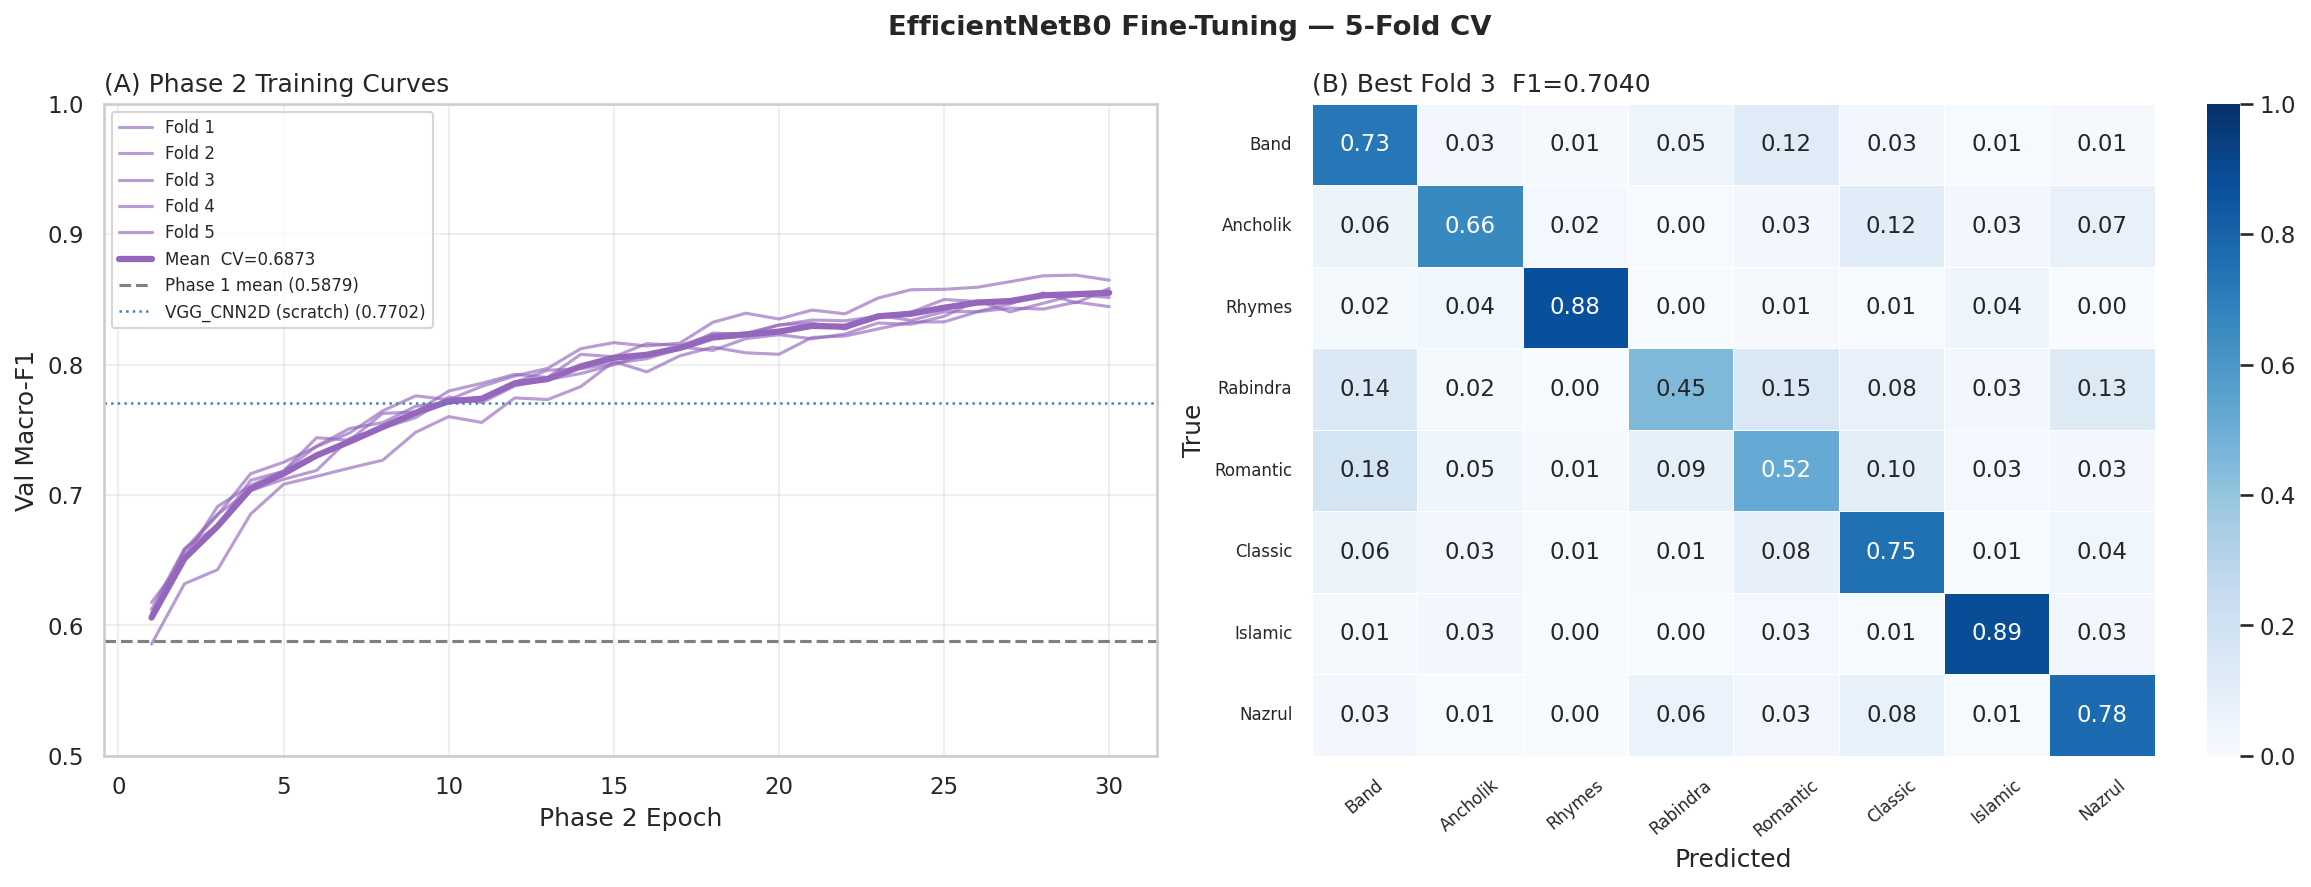

Saved: /kaggle/working/part5a_v3/figures/efficientnet_results.png


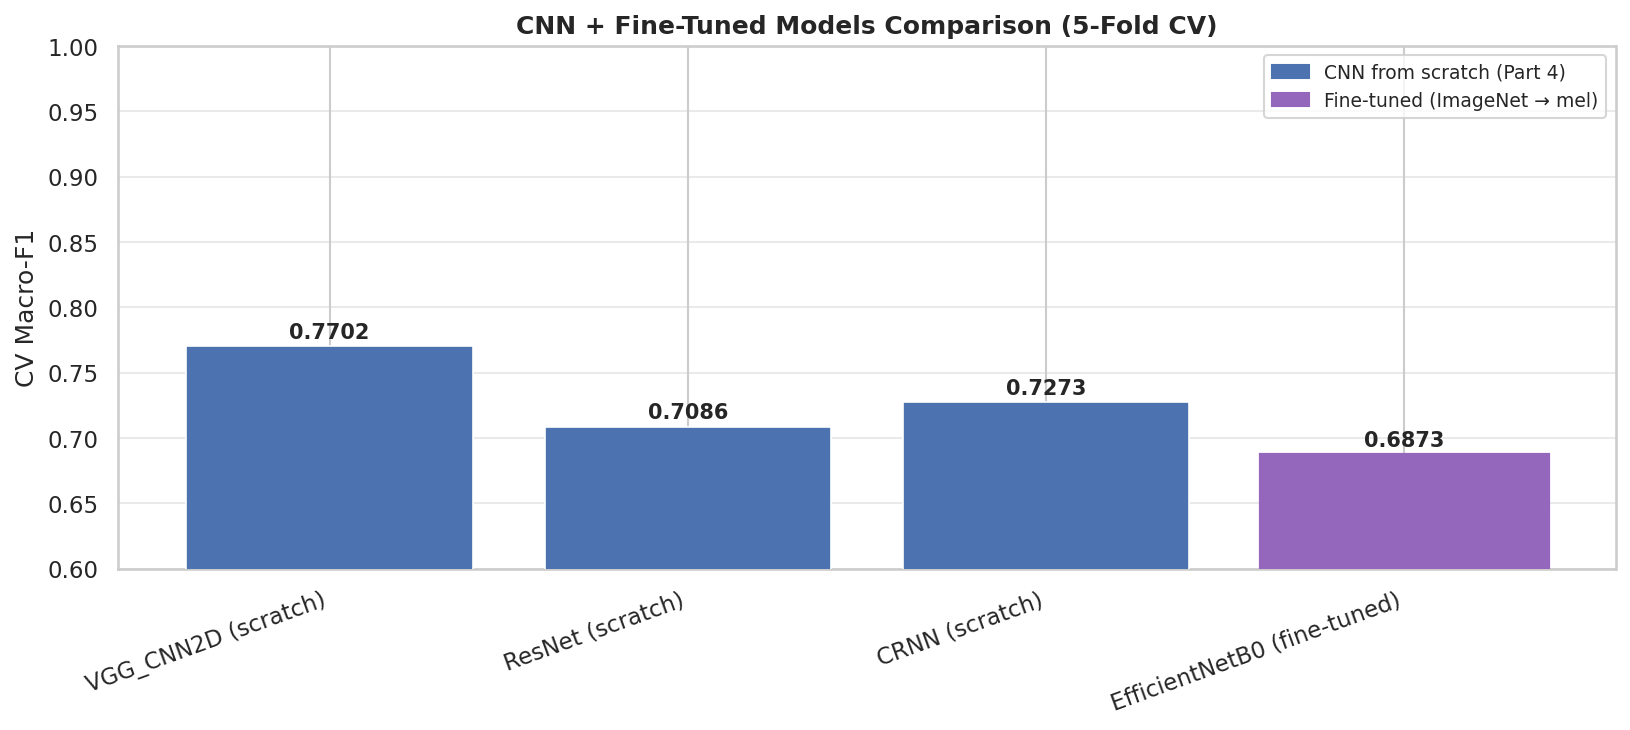

Saved: /kaggle/working/part5a_v3/figures/model_comparison.png


In [7]:
# ============================================================
# CELL 7 ▸ Results + Figures
# ============================================================
def to_py(obj):
    if isinstance(obj,dict):           return {k:to_py(v) for k,v in obj.items()}
    if isinstance(obj,(list,tuple)):   return [to_py(v) for v in obj]
    if isinstance(obj,np.ndarray):     return obj.tolist()
    if isinstance(obj,(np.integer,)):  return int(obj)
    if isinstance(obj,(np.floating,)): return float(obj)
    return obj

result_json = os.path.join(OUT_DIR,'part5a_v3_cv_results.json')
with open(result_json,'w') as f:
    json.dump(to_py({'EfficientNetB0_FT':
                     {'summary':eff_sum,'fold_metrics':CV_FOLD_MET}}), f, indent=2)

# Paper table
print('='*68)
print('  EfficientNetB0 Fine-Tuning — 5-Fold CV Results')
print('='*68)
print(f'  {"Fold":<6} {"Phase1":>8}  {"Phase2":>8}  {"Δ":>6}  '
      f'{"W-F1":>8}  {"Acc":>8}  {"Best_ep2":>8}')
print(f'  {"-"*6} {"-"*8}  {"-"*8}  {"-"*6}  {"-"*8}  {"-"*8}  {"-"*8}')
for k in range(N_FOLDS):
    mm=CV_FOLD_MET[k]
    print(f'  {k+1:<6} {mm["phase1_f1"]:>8.4f}  '
          f'{mm["macro_f1"]:>8.4f}  '
          f'{mm["macro_f1"]-mm["phase1_f1"]:>+6.4f}  '
          f'{mm["weighted_f1"]:>8.4f}  '
          f'{mm["accuracy"]:>8.4f}  {mm["best_epoch_p2"]:>8}')
print(f'  {"Mean":<6} {np.mean(P1_F1S):>8.4f}  '
      f'{eff_sum["macro_f1_mean"]:>8.4f}  '
      f'{eff_sum["macro_f1_mean"]-np.mean(P1_F1S):>+6.4f}')

print()
print('Per-class F1 (mean +/- std across 5 folds):')
for i,cls in enumerate(SHORT_NAMES):
    vals=[mm['per_class_f1'][i] for mm in CV_FOLD_MET]
    bar='█'*int(np.mean(vals)*25)
    print(f'  {cls:<12} {np.mean(vals):.4f}+/-{np.std(vals,ddof=1):.3f}  {bar}')

# Comparison with CNN models from Part 4
P4_RESULTS = {
    'VGG_CNN2D (scratch)' : 0.7702,
    'ResNet (scratch)'    : 0.7086,
    'CRNN (scratch)'      : 0.7273,
}
print(f'\\nComparison with Part 4 CNN models (scratch):')
for mname,f1 in P4_RESULTS.items():
    delta=eff_sum["macro_f1_mean"]-f1
    print(f'  {mname:<25} {f1:.4f}  →  EfficientNet: {delta:+.4f}')

# ── Fig 1: Phase 2 training curves ────────────────────────────
all_h = [mm['f1_history_p2'] for mm in CV_FOLD_MET if mm.get('f1_history_p2')]
fig, axes = plt.subplots(1,2,figsize=(16,6))
fig.suptitle('EfficientNetB0 Fine-Tuning — 5-Fold CV',fontweight='bold')

ax = axes[0]
max_l = max(len(h) for h in all_h)
for k,h in enumerate(all_h):
    ax.plot(range(1,len(h)+1),h,lw=1.5,alpha=0.65,
            color='#9467BD',label=f'Fold {k+1}')
padded=[h+[h[-1]]*(max_l-len(h)) for h in all_h]
mean_h=np.mean(padded,axis=0)
ax.plot(range(1,max_l+1),mean_h,lw=3,color='#9467BD',
        label=f'Mean  CV={eff_sum["macro_f1_mean"]:.4f}')
ax.axhline(np.mean(P1_F1S),color='gray',ls='--',lw=1.5,
           label=f'Phase 1 mean ({np.mean(P1_F1S):.4f})')
for mname,f1 in list(P4_RESULTS.items())[:1]:  # VGG reference
    ax.axhline(f1,color='steelblue',ls=':',lw=1.2,
               label=f'{mname} ({f1:.4f})')
ax.set_xlabel('Phase 2 Epoch'); ax.set_ylabel('Val Macro-F1')
ax.set_ylim(0.5,1); ax.grid(True,alpha=0.3); ax.legend(fontsize=8)
ax.set_title('(A) Phase 2 Training Curves',loc='left')

# ── Fig 2: confusion matrix best fold ─────────────────────────
best_k  = int(np.argmax([mm['macro_f1'] for mm in CV_FOLD_MET]))
y_te    = np.array(CV_FOLD_MET[best_k]['y_true'])
y_pred  = np.array(CV_FOLD_MET[best_k]['y_pred'])
cm      = confusion_matrix(y_te,y_pred,labels=list(range(N_CLASSES)))
with np.errstate(divide='ignore',invalid='ignore'):
    cm_n = np.where(cm.sum(1,keepdims=True)==0,0,
                    cm.astype(float)/cm.sum(1,keepdims=True))
sns.heatmap(cm_n,annot=True,fmt='.2f',cmap='Blues',
            xticklabels=SHORT_NAMES,yticklabels=SHORT_NAMES,
            linewidths=0.4,ax=axes[1],vmin=0,vmax=1)
axes[1].set_title(f'(B) Best Fold {best_k+1}  '
                  f'F1={CV_FOLD_MET[best_k]["macro_f1"]:.4f}',
                  loc='left')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')
axes[1].tick_params(axis='x',rotation=40,labelsize=8)
axes[1].tick_params(axis='y',rotation=0, labelsize=8)
plt.tight_layout()
fig_p=os.path.join(FIG_DIR,'efficientnet_results.png')
plt.savefig(fig_p); plt.show(); print(f'Saved: {fig_p}')

# ── Fig 3: Full model comparison bar chart ────────────────────
all_models_f1 = {**P4_RESULTS,
                 'EfficientNetB0 (fine-tuned)':eff_sum['macro_f1_mean']}
fig,ax = plt.subplots(figsize=(11,5))
names  = list(all_models_f1.keys())
vals   = list(all_models_f1.values())
colors_bar = ['#4C72B0']*3 + ['#9467BD']
bars   = ax.bar(range(len(names)),vals,color=colors_bar,
                edgecolor='white',lw=0.8,zorder=3)
bars[-1].set_edgecolor('#9467BD'); bars[-1].set_linewidth(2.5)
for bar,v in zip(bars,vals):
    ax.text(bar.get_x()+bar.get_width()/2,v+0.003,
            f'{v:.4f}',ha='center',va='bottom',fontsize=10,fontweight='bold')
ax.set_xticks(range(len(names))); ax.set_xticklabels(names,rotation=20,ha='right')
ax.set_ylabel('CV Macro-F1'); ax.set_ylim(0.6,1.0)
ax.yaxis.grid(True,alpha=0.4); ax.set_axisbelow(True)
ax.set_title('CNN + Fine-Tuned Models Comparison (5-Fold CV)',fontweight='bold')
import matplotlib.patches as mpatches
patches=[mpatches.Patch(color='#4C72B0',label='CNN from scratch (Part 4)'),
         mpatches.Patch(color='#9467BD',label='Fine-tuned (ImageNet → mel)')]
ax.legend(handles=patches,fontsize=9)
plt.tight_layout()
fig_p2=os.path.join(FIG_DIR,'model_comparison.png')
plt.savefig(fig_p2); plt.show(); print(f'Saved: {fig_p2}')

In [8]:
# ============================================================
# CELL 8 ▸ Save + ZIP
# ============================================================
zip_path = os.path.join(WORK_DIR,'part5a_v3.zip')
print(f'Creating {zip_path} ...')

with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as zf:
    bm = os.path.join(MDL_DIR,'efficientnet_best.keras')
    if os.path.exists(bm):
        zf.write(bm,'models/efficientnet_best.keras')
        print(f'  + models/efficientnet_best.keras  '
              f'{os.path.getsize(bm)/1e6:.1f} MB')
    zf.write(result_json,'part5a_v3_cv_results.json')
    print(f'  + part5a_v3_cv_results.json  ← needed by Part 5C & Part 6')
    for fname in sorted(os.listdir(FIG_DIR)):
        if fname.endswith('.png'):
            fp=os.path.join(FIG_DIR,fname)
            zf.write(fp,f'figures/{fname}')
            print(f'  + figures/{fname}')
    for fname in sorted(os.listdir(LOG_DIR)):
        fp=os.path.join(LOG_DIR,fname)
        zf.write(fp,f'logs/{fname}')
    print(f'  + logs/ ({len(os.listdir(LOG_DIR))} files)')

zip_sz = os.path.getsize(zip_path)/1e6
m,s,c  = eff_sum['macro_f1_mean'],eff_sum['macro_f1_std'],eff_sum['macro_f1_ci95']

print()
print('='*65)
print('  PART 5A v3 COMPLETE — EfficientNetB0 Fine-Tuning')
print('='*65)
print(f'  ZIP      : {zip_path}  ({zip_sz:.1f} MB)')
print(f'  Macro-F1 : {m:.4f} +/- {s:.4f}  '
      f'95%CI [{m-c:.4f}, {m+c:.4f}]')
print()
print('  Results for paper (all 5-fold CV):')
print(f'    VGG-CNN2D     (scratch) : 0.7702')
print(f'    ResNet-CNN2D  (scratch) : 0.7086')
print(f'    CRNN          (scratch) : 0.7273')
print(f'    EfficientNetB0 (fine-tuned): {m:.4f}  ← Part 5A v3')
print()
print('  NEXT: Ask for Part 5B (AST with pre-cached features)')
print('  Part 5B will use ASTFeatureExtractor output pre-cached to disk')
print('  to avoid the 137 min/fold CPU bottleneck from the old version.')

Creating /kaggle/working/part5a_v3.zip ...
  + models/efficientnet_best.keras  51.3 MB
  + part5a_v3_cv_results.json  ← needed by Part 5C & Part 6
  + figures/efficientnet_results.png
  + figures/model_comparison.png
  + logs/ (5 files)

  PART 5A v3 COMPLETE — EfficientNetB0 Fine-Tuning
  ZIP      : /kaggle/working/part5a_v3.zip  (47.0 MB)
  Macro-F1 : 0.6873 +/- 0.0143  95%CI [0.6696, 0.7050]

  Results for paper (all 5-fold CV):
    VGG-CNN2D     (scratch) : 0.7702
    ResNet-CNN2D  (scratch) : 0.7086
    CRNN          (scratch) : 0.7273
    EfficientNetB0 (fine-tuned): 0.6873  ← Part 5A v3

  NEXT: Ask for Part 5B (AST with pre-cached features)
  Part 5B will use ASTFeatureExtractor output pre-cached to disk
  to avoid the 137 min/fold CPU bottleneck from the old version.
